# Part Usage Across the Sequenced Circuits

In [1]:
## CONFIG ##

# Reload configs on each run.
%load_ext autoreload
%autoreload 2

import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from matplotlib.ticker import FixedLocator, ScalarFormatter

import config
from config import CRYPTIC_OPTION, FILTERED_CSV, OUT_DIR, PART_BP, REMOVED_CSV, SLOTS
from assembly import RESIDUAL, assign_slots, decompose

plt.rcParams["figure.dpi"] = 100
plt.rcParams["savefig.dpi"] = 100


## PARTS ##

# The four kinds a genotype is made of
PART_CATEGORY = {
    **{part: "promoter" for part in
       ("pTac", "pTet", "pSrpR", "pBAD", "pTra", "pBM3R1")},
    **{part: "CDS" for part in
       ("AraC", "PhlF", "SrpR", "BM3R1", "TraRW")},
    **{part: "terminator" for part in ("tSrpR", "tPhlF")},
    **{part: "spacer" for part in ("Spacer1", "Spacer2", "Spacer3")},
}
CATEGORY_ORDER = ("promoter", "CDS", "terminator", "spacer")

# Fixed hue per category, colour-vision checked
CATEGORY_COLOUR = {"promoter": "#2a78d6", "CDS": "#eb6834",
                   "terminator": "#1baf7a", "spacer": "#eda100"}

# Shape carries the category too
CATEGORY_MARKER = {"promoter": "o", "CDS": "s", "terminator": "^", "spacer": "D"}


## SLOTS ##

# One muted hue per slot
SLOT_COLOUR = {"a": "#8fabdc", "b": "#d65f5f", "c": "#e69352"}
SLOT_ORDER = ("a", "b", "c")

# Residual: parts of an invalid assembly no legal chain covers
SLOT_COLOUR[RESIDUAL] = "#d9d9d9"

# Shape carries the slot too
SLOT_MARKER = {"a": "o", "b": "s", "c": "^"}


## AVAILABILITY ##

# One colour for every part
AVAILABILITY_COLOUR = "#7fbf9b"


## OUTPUT ##

# every figure, at print resolution for the thesis
PRINT_DPI = 300
OCCURRENCES_PNG = OUT_DIR / "part_histo.png"
OCCURRENCES_LENGTH_PNG = OUT_DIR / "part_scatter.png"
SLOT_USES_PNG = OUT_DIR / "composites_histo.png"
SCATTER_PNG = OUT_DIR / "composites_scatter.png"
REMOVED_PNG = OUT_DIR / "part_histo_removed.png"
INVALID_PNG = OUT_DIR / "part_histo_invalid.png"
AVAILABILITY_PNG = OUT_DIR / "part_availability.png"
AVAILABILITY_CRYPTIC_PNG = OUT_DIR / "part_availability_cryptic.png"

## Load

In [2]:
# From michiel_lib_genotype.ipynb
# keep_default_na=False: an absent genotype is an empty string, not NaN
filtered = pd.read_csv(FILTERED_CSV, keep_default_na=False, na_values=[""])

# Valid assemblies only
valid = filtered[filtered.valid].copy()
valid["parts"] = valid["circuit_parts"].str.split("-")

print(f"{len(filtered)} filtered circuits, {len(valid)} valid")
print(f"{valid['parts'].map(len).sum()} part occurrences, "
      f"{valid['parts'].map(len).min()}-{valid['parts'].map(len).max()} per circuit")

# Filtered-out and invalid circuits, kept apart
removed = pd.read_csv(REMOVED_CSV, keep_default_na=False, na_values=[""])
# circuit_60 and circuit_64 carry a genotype but no recognised part, so this column reads NaN
removed["parts"] = removed["circuit_parts"].fillna("").str.split("-")
invalid = filtered[~filtered.valid].copy()
invalid["parts"] = invalid["circuit_parts"].str.split("-")

print(f"{len(removed)} filtered out, {len(invalid)} invalid")

68 filtered circuits, 58 valid
559 part occurrences, 8-12 per circuit
18 filtered out, 10 invalid


## 1: Part Occurrences

In [3]:
# occurrences counts every copy; circuits counts the genotypes carrying at least one
occurrences = pd.Series([part for parts in valid["parts"] for part in parts]).value_counts()
circuits = pd.Series([part for parts in valid["parts"] for part in set(parts)]).value_counts()

# Every part the scheme defines, used or not
usage = pd.DataFrame(index=pd.Index(PART_CATEGORY, name="part"))
usage["category"] = usage.index.map(PART_CATEGORY)
usage["length_bp"] = usage.index.map(PART_BP)
usage["occurrences"] = occurrences.reindex(usage.index).fillna(0).astype(int)
usage["circuits"] = circuits.reindex(usage.index).fillna(0).astype(int)
usage["share_of_circuits"] = (usage["circuits"] / len(valid)).round(3)

# Slot of every occurrence; valid circuits have no residual
by_slot = pd.DataFrame([(part, slot) for parts in valid["parts"]
                        for part, slot in zip(parts, assign_slots(parts, SLOTS))],
                       columns=["part", "slot"]).value_counts().unstack(fill_value=0)
assert RESIDUAL not in by_slot.columns, "a valid circuit cannot carry a residual part"
usage[list(SLOT_ORDER)] = by_slot.reindex(index=usage.index,
                                          columns=list(SLOT_ORDER)).fillna(0).astype(int)
assert usage[list(SLOT_ORDER)].to_numpy().sum() == usage["occurrences"].sum()

usage = usage.sort_values(["category", "occurrences"], ascending=[True, False])

print(usage.to_string())

           category  length_bp  occurrences  circuits  share_of_circuits   a   b   c
part                                                                                
AraC            CDS        840           63        47              0.810  63   0   0
PhlF            CDS        603           63        47              0.810  63   0   0
SrpR            CDS        642           53        42              0.724  53   0   0
BM3R1           CDS        579           43        32              0.552   0   2  41
TraRW           CDS        705           15        14              0.241   0   0  15
pSrpR      promoter         82           57        43              0.741   0  57   0
pTra       promoter         54           57        43              0.741   0  57   0
pTac       promoter         71           56        42              0.724  53   3   0
pBAD       promoter        331           27        21              0.362   0  27   0
pTet       promoter         74            6         6            

wrote /home/ado/mscr/dev/seq/out/part_histo.png


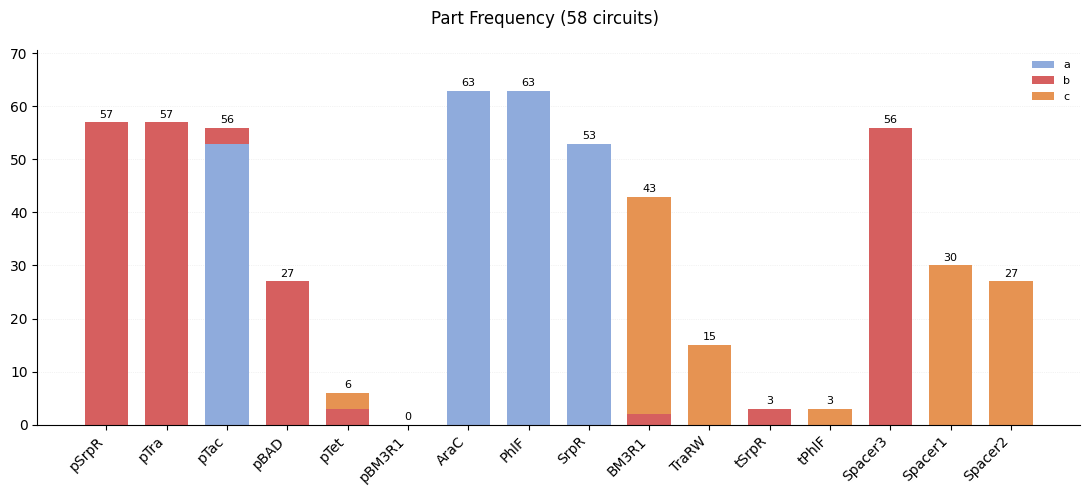

In [ ]:
# ordered by category then count, so the four kinds read as blocks
ordered = pd.concat([usage[usage["category"] == category].sort_values("occurrences",
                                                                      ascending=False)
                     for category in CATEGORY_ORDER])

fig, ax = plt.subplots(figsize=(11, 5))
bottom = pd.Series(0, index=ordered.index)
for slot in SLOT_ORDER:
    ax.bar(range(len(ordered)), ordered[slot], width=0.72, bottom=bottom,
           color=SLOT_COLOUR[slot], linewidth=0)
    bottom += ordered[slot]

# Totals on bars: fills are below 3:1 contrast
for position, count in enumerate(ordered["occurrences"]):
    ax.annotate(f"{count}", (position, count), ha="center", va="bottom", fontsize=8,
                xytext=(0, 2), textcoords="offset points")

ax.set_xticks(range(len(ordered)))
ax.set_xticklabels(ordered.index, rotation=45, ha="right")
ax.set_ylim(0, ordered["occurrences"].max() * 1.12)
# SLOT_ORDER only: no leftover parts in valid circuits
ax.legend(handles=[Patch(facecolor=SLOT_COLOUR[slot], label=slot) for slot in SLOT_ORDER],
          fontsize=8, frameon=False)
ax.grid(True, axis="y", ls=":", alpha=0.3, linewidth=0.5)
ax.set_axisbelow(True)
for spine in ("top", "right"):
    ax.spines[spine].set_visible(False)
fig.suptitle(f"Part Frequency ({len(valid)} circuits)")
plt.tight_layout()
fig.savefig(OCCURRENCES_PNG, dpi=PRINT_DPI, bbox_inches="tight", pad_inches=0.02)
print(f"wrote {OCCURRENCES_PNG}")
plt.show()

wrote /home/ado/mscr/dev/seq/out/part_scatter.png


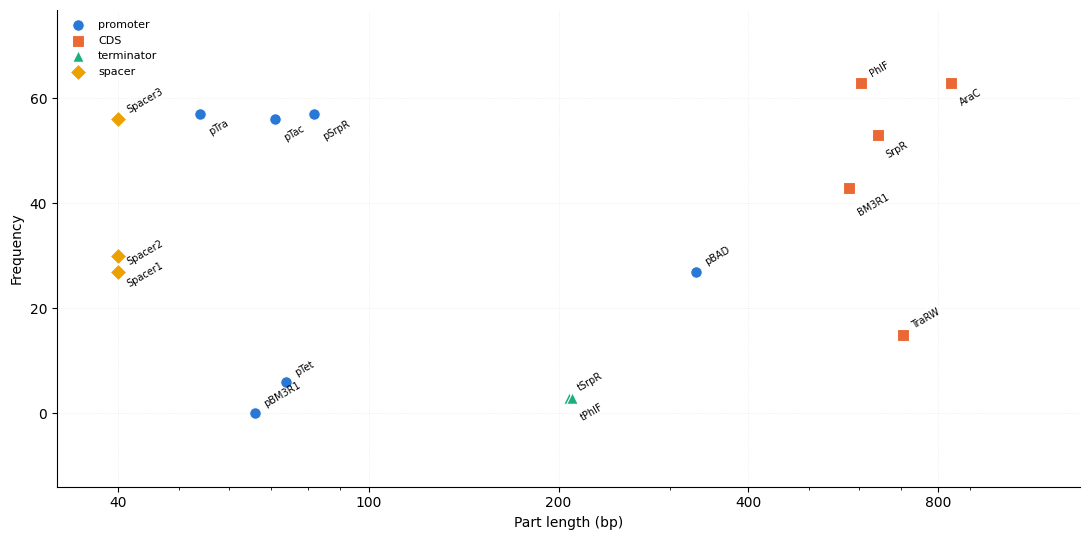

In [5]:
fig, ax = plt.subplots(figsize=(11, 5.5))
for category in CATEGORY_ORDER:
    points = usage[usage["category"] == category]
    ax.scatter(points["length_bp"], points["occurrences"], s=70, marker=CATEGORY_MARKER[category],
               color=CATEGORY_COLOUR[category], edgecolor="white", linewidth=0.8, zorder=3,
               label=category)

# Labels alternate above and below the point
for index, row in enumerate(usage.sort_values(["length_bp", "occurrences"]).itertuples()):
    above = index % 2 == 0
    ax.annotate(row.Index, (row.length_bp, row.occurrences), rotation=30, fontsize=7, ha="left",
                va="bottom" if above else "top", xytext=(5, 3 if above else -3),
                textcoords="offset points")

ax.set_xscale("log")
ax.xaxis.set_major_locator(FixedLocator([40, 100, 200, 400, 800]))
ax.xaxis.set_major_formatter(ScalarFormatter())
ax.set_xlim(usage["length_bp"].min() * 0.8, usage["length_bp"].max() * 1.6)
ax.set_ylim(-14, usage["occurrences"].max() * 1.22)
ax.set_xlabel("Part length (bp)")
ax.set_ylabel("Frequency")
ax.legend(fontsize=8, frameon=False, loc="upper left")
ax.grid(True, ls=":", alpha=0.3, linewidth=0.5)
ax.set_axisbelow(True)
for spine in ("top", "right"):
    ax.spines[spine].set_visible(False)
plt.tight_layout()
fig.savefig(OCCURRENCES_LENGTH_PNG, dpi=PRINT_DPI, bbox_inches="tight", pad_inches=0.02)
print(f"wrote {OCCURRENCES_LENGTH_PNG}")
plt.show()

## 2: Slot Composition

In [6]:
assignments = [(slot, "_".join(option)) for parts in valid["parts"]
               for slot, option in decompose(parts, SLOTS)]

# Every option the scheme offers, used or not
# length_bp sums the parts as named; the insulators between them are not counted
options = pd.DataFrame([(slot, "_".join(option), sum(PART_BP[part] for part in option))
                        for slot, choices in SLOTS.items() for option in choices],
                       columns=["slot", "option", "length_bp"])
used = pd.Series(assignments).value_counts()
options["uses"] = [used.get((row.slot, row.option), 0) for row in options.itertuples()]
options = options.sort_values(["slot", "uses"], ascending=[True, False]).reset_index(drop=True)

print(f"{len(valid) * 6} slots filled across {len(valid)} circuits\n")
print(options.to_string(index=False))

348 slots filled across 58 circuits

slot                 option  length_bp  uses
   a              AraC_PhlF       1443    63
   a              pTac_SrpR        713    53
   b                Spacer3         40    56
   b             pSrpR_pTra        136    30
   b        pSrpR_pTra_pBAD        467    27
   b  pTet_pTac_tSrpR_BM3R1        932     2
   b        pTet_pTac_tSrpR        353     1
   b             pTac_tSrpR        279     0
   b                   pTet         74     0
   c                  BM3R1        579    41
   c                Spacer1         40    30
   c                Spacer2         40    27
   c                  TraRW        705    15
   c             pTet_tPhlF        284     3
   c             pTac_tPhlF        281     0
   c      pTet_BM3R1_pBM3R1        719     0
   c pTet_BM3R1_pBM3R1_pBAD       1050     0
   c                   pTet         74     0
   c                   pTra         54     0


wrote /home/ado/mscr/dev/seq/out/composites_histo.png


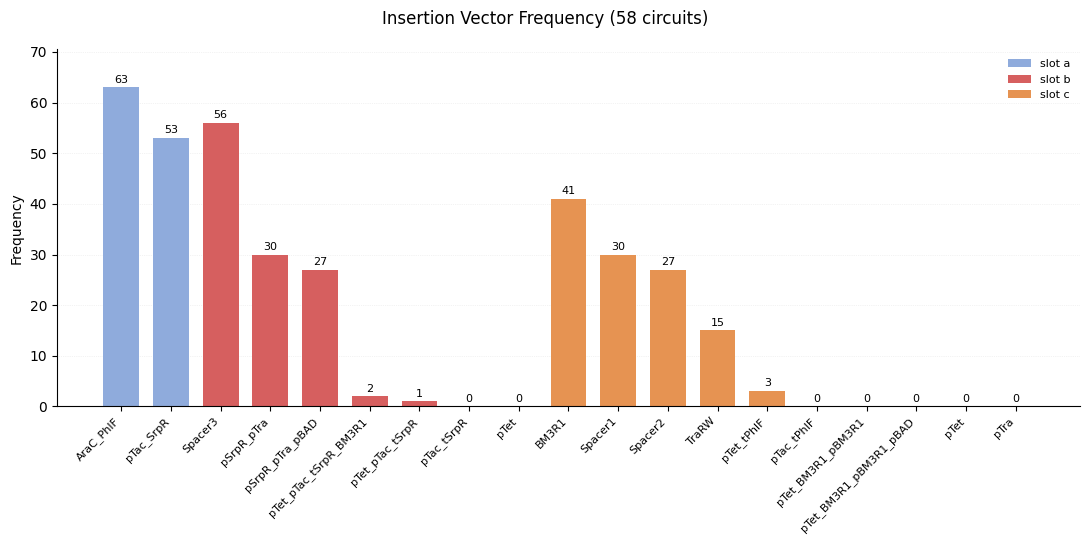

In [7]:
fig, ax = plt.subplots(figsize=(11, 5.5))
bars = ax.bar(range(len(options)), options["uses"], width=0.72,
              color=[SLOT_COLOUR[slot] for slot in options["slot"]], linewidth=0)

for bar, count in zip(bars, options["uses"]):
    ax.annotate(f"{count}", (bar.get_x() + bar.get_width() / 2, bar.get_height()),
                ha="center", va="bottom", fontsize=8, xytext=(0, 2),
                textcoords="offset points")

ax.set_xticks(range(len(options)))
ax.set_xticklabels(options["option"], rotation=45, ha="right", fontsize=8)
ax.set_ylabel("Frequency")
ax.set_ylim(0, max(options["uses"].max() * 1.12, 1))
ax.legend(handles=[Patch(facecolor=SLOT_COLOUR[slot], label=f"slot {slot}")
                   for slot in ("a", "b", "c")], fontsize=8, frameon=False)
ax.grid(True, axis="y", ls=":", alpha=0.3, linewidth=0.5)
ax.set_axisbelow(True)
for spine in ("top", "right"):
    ax.spines[spine].set_visible(False)
fig.suptitle(f"Insertion Vector Frequency ({len(valid)} circuits)")
plt.tight_layout()
fig.savefig(SLOT_USES_PNG, dpi=PRINT_DPI, bbox_inches="tight", pad_inches=0.02)
print(f"wrote {SLOT_USES_PNG}")
plt.show()

wrote /home/ado/mscr/dev/seq/out/composites_scatter.png: 15 of 19 options named


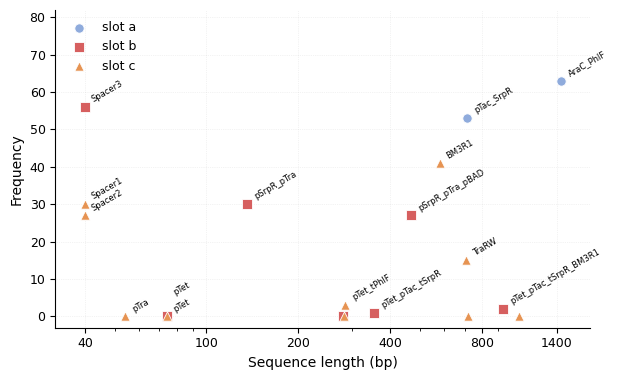

In [8]:
# Sized for \textwidth
fig, ax = plt.subplots(figsize=(6.3, 3.9))
for slot in ("a", "b", "c"):
    points = options[options["slot"] == slot]
    ax.scatter(points["length_bp"], points["uses"], s=45, marker=SLOT_MARKER[slot],
               color=SLOT_COLOUR[slot], edgecolor="white", linewidth=0.6, zorder=3,
               label=f"slot {slot}")

# Unused options unlabelled, except bare pTet and pTra
named = options[(options["uses"] > 0) | options["option"].isin(["pTet", "pTra"])]

# pTet in slots b and c at the same length: labels stepped apart
LABEL_OFFSET = {("pTet", "c"): (4, 14)}

for row in named.itertuples():
    ax.annotate(row.option, (row.length_bp, row.uses), rotation=30, fontsize=6,
                ha="left", va="bottom",
                xytext=LABEL_OFFSET.get((row.option, row.slot), (4, 2)),
                textcoords="offset points")

ax.set_xscale("log")
ax.xaxis.set_major_locator(FixedLocator([40, 100, 200, 400, 800, 1400]))
ax.xaxis.set_major_formatter(ScalarFormatter())
ax.set_xlim(options["length_bp"].min() * 0.8, options["length_bp"].max() * 1.25)
ax.set_ylim(-3, options["uses"].max() * 1.3)
ax.set_xlabel("Sequence length (bp)", fontsize=10)
ax.set_ylabel("Frequency", fontsize=10)
ax.tick_params(labelsize=9)
ax.legend(fontsize=9, frameon=False, loc="upper left")
ax.grid(True, ls=":", alpha=0.3, linewidth=0.5)
ax.set_axisbelow(True)
for spine in ("top", "right"):
    ax.spines[spine].set_visible(False)
# no title: the thesis caption carries it
plt.tight_layout()
fig.savefig(SCATTER_PNG, dpi=PRINT_DPI, bbox_inches="tight", pad_inches=0.02)
print(f"wrote {SCATTER_PNG}: {len(named)} of {len(options)} options named")
plt.show()

In [9]:
# Spacer share of the slots on offer; each slot kind filled twice per circuit
slots_available = len(valid) * 2
spacer_12 = options.loc[options["option"].isin(["Spacer1", "Spacer2"]), "uses"].sum()
spacer_3 = options.loc[options["option"] == "Spacer3", "uses"].sum()

print(f"{len(valid)} valid circuits, {slots_available} of each slot filled")
print(f"Spacer1 + Spacer2   {spacer_12:3d} / {slots_available} = "
      f"{spacer_12 / slots_available:.3f}")
print(f"Spacer3             {spacer_3:3d} / {slots_available} = "
      f"{spacer_3 / slots_available:.3f}")

58 valid circuits, 116 of each slot filled
Spacer1 + Spacer2    57 / 116 = 0.491
Spacer3              56 / 116 = 0.483


## 3: Part Availability

In [10]:
# Cryptic option dropped from the weighting; the second figure keeps it
buildable = {slot: [option for option in choices if option != CRYPTIC_OPTION]
             for slot, choices in SLOTS.items()}

# Weight by how many options each slot offers
availability = pd.DataFrame(index=usage.index)
availability["occurrences"] = usage["occurrences"]
for column, scheme in (("offered", buildable), ("offered_cryptic", SLOTS)):
    counts = pd.Series(0.0, index=usage.index)
    for slot, choices in scheme.items():
        for option in choices:
            for part in option:
                counts[part] += len(valid) * 2 / len(choices)
    availability[column] = counts

# Parts the scheme never offers left out
assert (availability["offered"] > 0).all()
availability["used_over_offered"] = availability["occurrences"] / availability["offered"]

# Shared limits and label offsets across both figures
xlim = (0, availability[["offered", "offered_cryptic"]].to_numpy().max() * 1.12)
ylim = (-7, availability["occurrences"].max() * 1.20)
# AraC and PhlF are one option, one point
LABEL_OFFSET = {"PhlF": (4, -12), "Spacer2": (4, -12), "pBM3R1": (4, -12)}

print(f"{availability['occurrences'].sum()} occurrences against "
      f"{availability['offered'].sum():.0f} expected under uniform choice over the options")
print(availability.sort_values("offered").round(2).to_string())

559 occurrences against 700 expected under uniform choice over the options
         occurrences  offered  offered_cryptic  used_over_offered
part                                                             
TraRW             15    11.60            11.60               1.29
Spacer2           27    11.60            11.60               2.33
Spacer1           30    11.60            11.60               2.59
Spacer3           56    19.33            16.57               2.90
pBM3R1             0    23.20            23.20               0.00
tPhlF              3    23.20            23.20               0.13
pBAD              27    30.93            28.17               0.87
pSrpR             57    38.67            33.14               1.47
tSrpR              3    38.67            49.71               0.08
pTra              57    50.27            44.74               1.13
BM3R1             43    54.13            51.37               0.79
SrpR              53    58.00            58.00               0.91
P

wrote /home/ado/mscr/dev/seq/out/part_availability.png


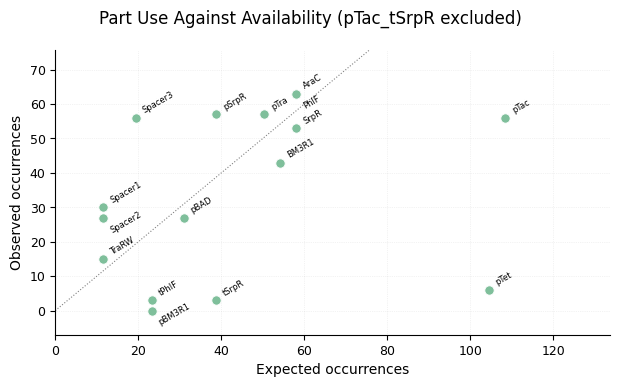

In [11]:
# Sized for \textwidth
fig, ax = plt.subplots(figsize=(6.3, 3.9))
# On the line: used as often as uniform choice would give
ax.plot(xlim, xlim, ls=":", color="0.5", linewidth=0.8, zorder=1)
ax.scatter(availability["offered"], availability["occurrences"], s=45,
           color=AVAILABILITY_COLOUR, edgecolor="white", linewidth=0.6, zorder=3)

for row in availability.itertuples():
    ax.annotate(row.Index, (row.offered, row.occurrences), rotation=30, fontsize=6,
                ha="left", va="bottom", xytext=LABEL_OFFSET.get(row.Index, (4, 2)),
                textcoords="offset points")

ax.set_xlim(*xlim)
ax.set_ylim(*ylim)
ax.set_xlabel("Expected occurrences", fontsize=10)
ax.set_ylabel("Observed occurrences", fontsize=10)
ax.tick_params(labelsize=9)
ax.grid(True, ls=":", alpha=0.3, linewidth=0.5)
ax.set_axisbelow(True)
for spine in ("top", "right"):
    ax.spines[spine].set_visible(False)
fig.suptitle("Part Use Against Availability (pTac_tSrpR excluded)")
plt.tight_layout()
fig.savefig(AVAILABILITY_PNG, dpi=PRINT_DPI, bbox_inches="tight", pad_inches=0.02)
print(f"wrote {AVAILABILITY_PNG}")
plt.show()

wrote /home/ado/mscr/dev/seq/out/part_availability_cryptic.png


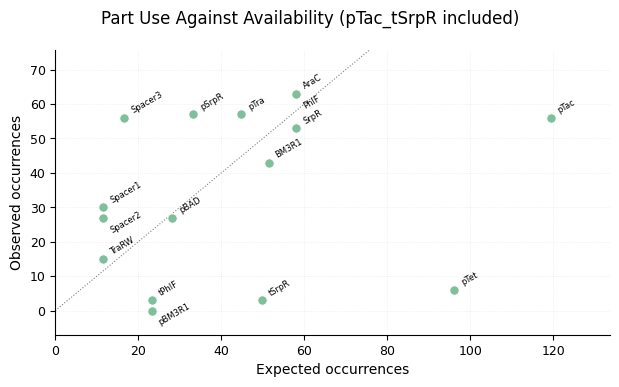

In [12]:
# Sized for \textwidth
fig, ax = plt.subplots(figsize=(6.3, 3.9))
# On the line: used as often as uniform choice would give
ax.plot(xlim, xlim, ls=":", color="0.5", linewidth=0.8, zorder=1)
ax.scatter(availability["offered_cryptic"], availability["occurrences"], s=45,
           color=AVAILABILITY_COLOUR, edgecolor="white", linewidth=0.6, zorder=3)

for row in availability.itertuples():
    ax.annotate(row.Index, (row.offered_cryptic, row.occurrences), rotation=30, fontsize=6,
                ha="left", va="bottom", xytext=LABEL_OFFSET.get(row.Index, (4, 2)),
                textcoords="offset points")

ax.set_xlim(*xlim)
ax.set_ylim(*ylim)
ax.set_xlabel("Expected occurrences", fontsize=10)
ax.set_ylabel("Observed occurrences", fontsize=10)
ax.tick_params(labelsize=9)
ax.grid(True, ls=":", alpha=0.3, linewidth=0.5)
ax.set_axisbelow(True)
for spine in ("top", "right"):
    ax.spines[spine].set_visible(False)
fig.suptitle("Part Use Against Availability (pTac_tSrpR included)")
plt.tight_layout()
fig.savefig(AVAILABILITY_CRYPTIC_PNG, dpi=PRINT_DPI, bbox_inches="tight", pad_inches=0.02)
print(f"wrote {AVAILABILITY_CRYPTIC_PNG}")
plt.show()

## 4: Excluded Circuits

In [13]:
# Occurrences count every copy, as in section 1
excluded = pd.DataFrame(index=pd.Index(PART_CATEGORY, name="part"))
excluded["category"] = excluded.index.map(PART_CATEGORY)
for column, frame in (("removed", removed), ("invalid", invalid)):
    counted = pd.Series([part for parts in frame["parts"] for part in parts if part]).value_counts()
    excluded[column] = counted.reindex(excluded.index).fillna(0).astype(int)
excluded["total"] = excluded["removed"] + excluded["invalid"]

print(f"{excluded['removed'].sum()} occurrences across {len(removed)} filtered out, "
      f"{excluded['invalid'].sum()} across {len(invalid)} invalid")
print(excluded.sort_values(["category", "total"], ascending=[True, False]).to_string())

# One part order for both figures
ordered = pd.concat([excluded[excluded["category"] == category].sort_values("total",
                                                                            ascending=False)
                     for category in CATEGORY_ORDER])

# Invalid assemblies: parts labelled one at a time, uncovered ones residual
INVALID_SLOTS = list(SLOT_ORDER) + [RESIDUAL]
invalid_slots = pd.DataFrame([(part, slot) for parts in invalid["parts"]
                              for part, slot in zip(parts, assign_slots(parts, SLOTS))],
                             columns=["part", "slot"]).value_counts().unstack(fill_value=0)
invalid_slots = invalid_slots.reindex(index=ordered.index,
                                      columns=INVALID_SLOTS).fillna(0).astype(int)
assert (invalid_slots.sum(axis=1) == ordered["invalid"]).all()

print(f"\n{invalid_slots[list(SLOT_ORDER)].to_numpy().sum()} of "
      f"{invalid_slots.to_numpy().sum()} invalid occurrences land in a slot, "
      f"{invalid_slots[RESIDUAL].sum()} residual")
print(invalid_slots[invalid_slots.sum(axis=1) > 0].to_string())

222 occurrences across 18 filtered out, 70 across 10 invalid
           category  removed  invalid  total
part                                        
PhlF            CDS       24        8     32
AraC            CDS       23        7     30
SrpR            CDS       24        6     30
BM3R1           CDS       13        6     19
TraRW           CDS        6        1      7
pTac       promoter       25        8     33
pSrpR      promoter       20        4     24
pTra       promoter       19        4     23
pBAD       promoter       13        5     18
pTet       promoter        4        1      5
pBM3R1     promoter        1        1      2
Spacer3      spacer       23       10     33
Spacer1      spacer       12        5     17
Spacer2      spacer       13        4     17
tSrpR    terminator        1        0      1
tPhlF    terminator        1        0      1

62 of 70 invalid occurrences land in a slot, 8 residual
slot     a  b  c  residual
part                      
pTac     6  0  0  

wrote /home/ado/mscr/dev/seq/out/part_histo_removed.png


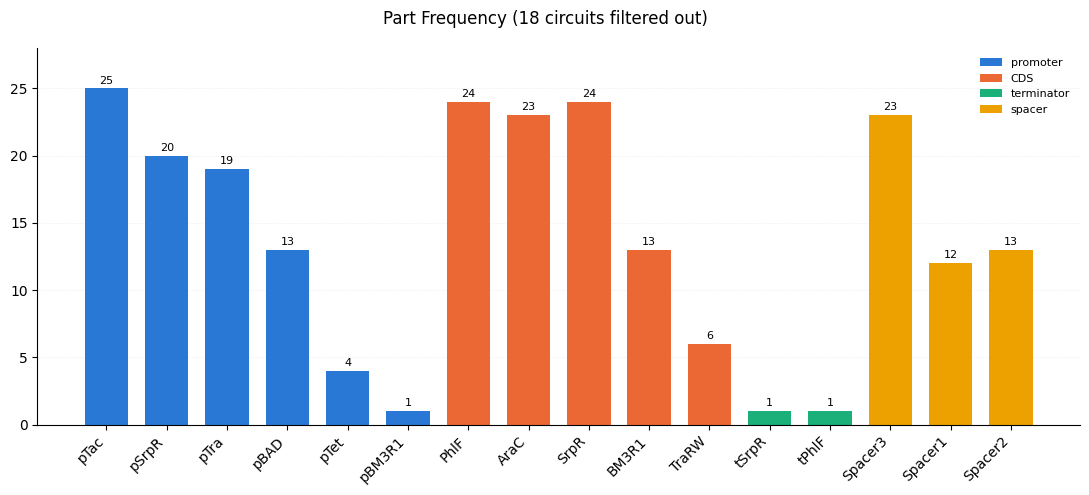

In [14]:
fig, ax = plt.subplots(figsize=(11, 5))
bars = ax.bar(range(len(ordered)), ordered["removed"], width=0.72,
              color=[CATEGORY_COLOUR[category] for category in ordered["category"]],
              linewidth=0)

# Totals on bars: fills are below 3:1 contrast
for bar, count in zip(bars, ordered["removed"]):
    ax.annotate(f"{count}", (bar.get_x() + bar.get_width() / 2, bar.get_height()),
                ha="center", va="bottom", fontsize=8, xytext=(0, 2),
                textcoords="offset points")

ax.set_xticks(range(len(ordered)))
ax.set_xticklabels(ordered.index, rotation=45, ha="right")
ax.set_ylim(0, ordered["removed"].max() * 1.12)
ax.legend(handles=[Patch(facecolor=CATEGORY_COLOUR[category], label=category)
                   for category in CATEGORY_ORDER], fontsize=8, frameon=False)
ax.grid(True, axis="y", ls=":", alpha=0.3, linewidth=0.5)
ax.set_axisbelow(True)
for spine in ("top", "right"):
    ax.spines[spine].set_visible(False)
fig.suptitle(f"Part Frequency ({len(removed)} circuits filtered out)")
plt.tight_layout()
fig.savefig(REMOVED_PNG, dpi=PRINT_DPI, bbox_inches="tight", pad_inches=0.02)
print(f"wrote {REMOVED_PNG}")
plt.show()

wrote /home/ado/mscr/dev/seq/out/part_histo_invalid.png


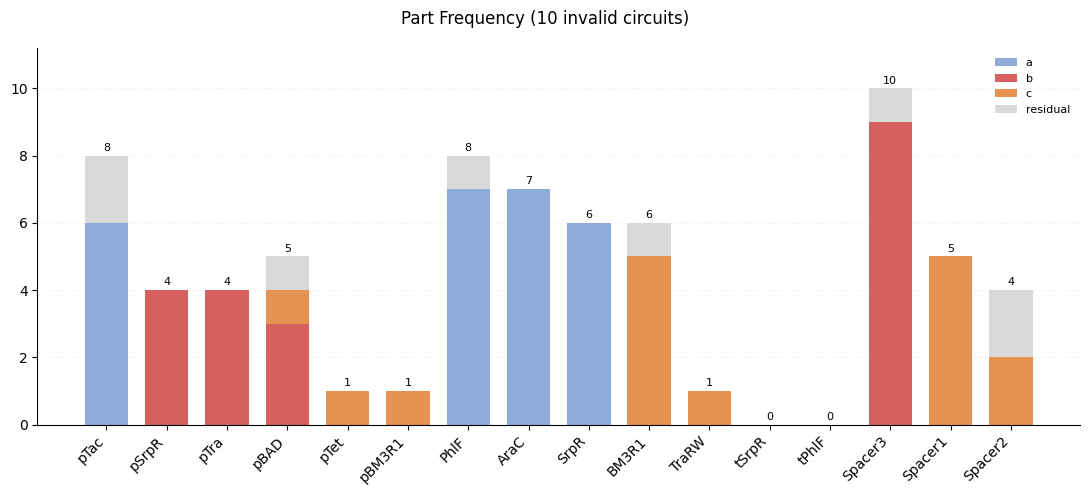

In [15]:
fig, ax = plt.subplots(figsize=(11, 5))
bottom = pd.Series(0, index=invalid_slots.index)
for slot in INVALID_SLOTS:
    ax.bar(range(len(invalid_slots)), invalid_slots[slot], width=0.72, bottom=bottom,
           color=SLOT_COLOUR[slot], linewidth=0)
    bottom += invalid_slots[slot]

# Totals on bars: fills are below 3:1 contrast
for position, count in enumerate(ordered["invalid"]):
    ax.annotate(f"{count}", (position, count), ha="center", va="bottom", fontsize=8,
                xytext=(0, 2), textcoords="offset points")

ax.set_xticks(range(len(ordered)))
ax.set_xticklabels(ordered.index, rotation=45, ha="right")
ax.set_ylim(0, ordered["invalid"].max() * 1.12)
# Residual drawn only here
ax.legend(handles=[Patch(facecolor=SLOT_COLOUR[slot], label=slot) for slot in INVALID_SLOTS],
          fontsize=8, frameon=False)
ax.grid(True, axis="y", ls=":", alpha=0.3, linewidth=0.5)
ax.set_axisbelow(True)
for spine in ("top", "right"):
    ax.spines[spine].set_visible(False)
fig.suptitle(f"Part Frequency ({len(invalid)} invalid circuits)")
plt.tight_layout()
fig.savefig(INVALID_PNG, dpi=PRINT_DPI, bbox_inches="tight", pad_inches=0.02)
print(f"wrote {INVALID_PNG}")
plt.show()